# Classifier-free guidance
生成我们指定的数据，而不是只拟合数据分布，目的是把无条件模型
$$ \epsilon_\theta(x_t,t) $$

变成条件模型：

$$ \epsilon_\theta(x_t,t,y), $$

让我们能够指定生成数字 \(y\in\{0,\ldots,9\}\)。

# 1. MNIST数据

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("device:", device)

device: cuda


In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5,),
        std=(0.5,),
    ),
])

dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True,
    drop_last=True,
    num_workers=0,
)

In [6]:
images, labels = next(iter(loader))

print("images:", images.shape)
print("labels:", labels.shape)
print("range:", images.min(), images.max())

images: torch.Size([128, 1, 28, 28])
labels: torch.Size([128])
range: tensor(-1.) tensor(1.)


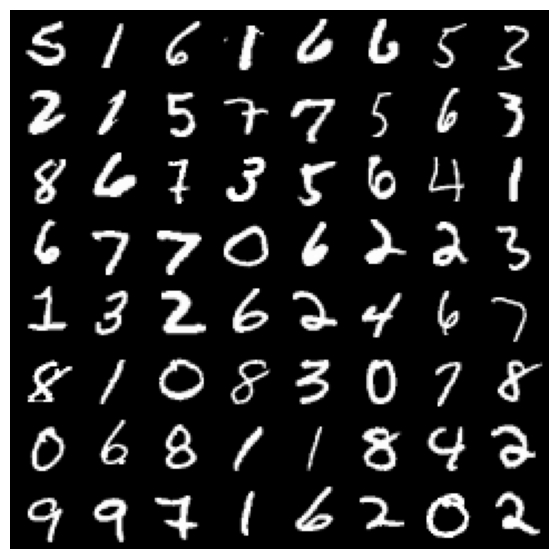

In [7]:
grid = make_grid(
    (images[:64] + 1) / 2,
    nrow=8,
)

plt.figure(figsize=(7, 7))
plt.imshow(
    grid.permute(1, 2, 0),
    cmap="gray",
)
plt.axis("off")
plt.show()

In [14]:
def q_sample_image(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    alpha_bar_t = alpha_bar[t].reshape(
        -1, 1, 1, 1
    )

    xt = (
        torch.sqrt(alpha_bar_t) * x0
        + torch.sqrt(
            1.0 - alpha_bar_t
        ) * noise
    )

    return xt

# 2. U-Net模型

In [8]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2

        frequencies = torch.exp(
            -math.log(10000)
            * torch.arange(
                half_dim,
                device=t.device,
            )
            / (half_dim - 1)
        )

        angles = (
            t.float()[:, None]
            * frequencies[None, :]
        )

        return torch.cat([
            torch.sin(angles),
            torch.cos(angles),
        ], dim=1)

In [9]:
class ResidualBlock(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        time_dim,
    ):
        super().__init__()

        self.norm1 = nn.GroupNorm(
            1,
            in_channels,
        )

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
        )

        self.norm2 = nn.GroupNorm(
            1,
            out_channels,
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
        )

        self.time_projection = nn.Linear(
            time_dim,
            out_channels,
        )

        if in_channels == out_channels:
            self.residual = nn.Identity()
        else:
            self.residual = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
            )

    def forward(self, x, time_embedding):
        h = self.norm1(x)
        h = F.silu(h)
        h = self.conv1(h)

        time_features = self.time_projection(
            time_embedding
        )

        time_features = time_features[
            :, :, None, None
        ]

        h = h + time_features

        h = self.norm2(h)
        h = F.silu(h)
        h = self.conv2(h)

        return h + self.residual(x)

In [18]:
# 需要增加条件输入
class TinyUNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()

        self.time_mlp = nn.Sequential(
            TimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )

        # 新增
        self.label_embedding = nn.Embedding(
            11,
            time_dim,
        )

        self.input_conv = nn.Conv2d(
            1,
            32,
            kernel_size=3,
            padding=1,
        )

        # 28 × 28
        self.down_block1 = ResidualBlock(
            32,
            64,
            time_dim,
        )

        # 14 × 14
        self.down_block2 = ResidualBlock(
            64,
            128,
            time_dim,
        )

        self.downsample = nn.AvgPool2d(2)

        # 7 × 7
        self.middle_block = ResidualBlock(
            128,
            128,
            time_dim,
        )

        # 7 -> 14
        self.upsample2 = nn.ConvTranspose2d(
            128,
            128,
            kernel_size=2,
            stride=2,
        )

        self.up_block2 = ResidualBlock(
            128 + 128,
            64,
            time_dim,
        )

        # 14 -> 28
        self.upsample1 = nn.ConvTranspose2d(
            64,
            64,
            kernel_size=2,
            stride=2,
        )

        self.up_block1 = ResidualBlock(
            64 + 64,
            32,
            time_dim,
        )

        self.output_norm = nn.GroupNorm(
            1,
            32,
        )

        self.output_conv = nn.Conv2d(
            32,
            1,
            kernel_size=3,
            padding=1,
        )

    def forward(self, x, t, labels):
        time_embedding = self.time_mlp(t)

        label_embedding = self.label_embedding(
            labels
        )

        conditioning = (
            time_embedding
            + label_embedding
        )

        x = self.input_conv(x)

        skip1 = self.down_block1(
            x,
            conditioning,
        )

        x = self.downsample(skip1)

        skip2 = self.down_block2(
            x,
            conditioning,
        )

        x = self.downsample(skip2)

        x = self.middle_block(
            x,
            conditioning,
        )

        x = self.upsample2(x)

        x = torch.cat(
            [x, skip2],
            dim=1,
        )

        x = self.up_block2(
            x,
            conditioning,
        )

        x = self.upsample1(x)

        x = torch.cat(
            [x, skip1],
            dim=1,
        )

        x = self.up_block1(
            x,
            conditioning,
        )

        x = self.output_norm(x)
        x = F.silu(x)
        x = self.output_conv(x)

        return x

# 3. 训练模型

In [19]:
T = 1000

beta = torch.linspace(
    1e-4,
    0.02,
    T,
    device=device,
)

alpha = 1.0 - beta
alpha_bar = torch.cumprod(
    alpha,
    dim=0,
)

print(alpha_bar[0].item())
print(alpha_bar[-1].item())

0.9998999834060669
4.035829260828905e-05


In [20]:
conditional_model = TinyUNet().to(device)

optimizer = torch.optim.Adam(
    conditional_model.parameters(),
    lr=2e-4,
)

In [ ]:
epochs = 10
null_class = 10
condition_drop_probability = 0.1
loss_history = []

conditional_model.train()

for epoch in range(epochs):
    total_loss = 0.0

    for x0, labels in loader:
        x0 = x0.to(device)
        labels = labels.to(device)

        batch_size = x0.shape[0]

        t = torch.randint(
            0,
            T,
            (batch_size,),
            device=device,
        )

        noise = torch.randn_like(x0)

        xt = q_sample_image(
            x0,
            t,
            noise,
        )

        # 随机选择需要丢弃条件的样本
        drop_mask = (
            torch.rand(
                batch_size,
                device=device,
            )
            < condition_drop_probability
        )

        training_labels = labels.clone()

        training_labels[drop_mask] = (
            null_class
        )

        predicted_noise = conditional_model(
            xt,
            t,
            training_labels,
        )

        loss = F.mse_loss(
            predicted_noise,
            noise,
        )

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            conditional_model.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        loss_history.append(loss.item())
        total_loss += loss.item()

    print(
        f"epoch={epoch + 1}, "
        f"loss={total_loss / len(loader):.4f}"
    )

epoch=1, loss=0.0841
epoch=2, loss=0.0362
epoch=3, loss=0.0311
epoch=4, loss=0.0293
epoch=5, loss=0.0276
epoch=6, loss=0.0265
epoch=7, loss=0.0259
epoch=8, loss=0.0255
epoch=9, loss=0.0252
epoch=10, loss=0.0247


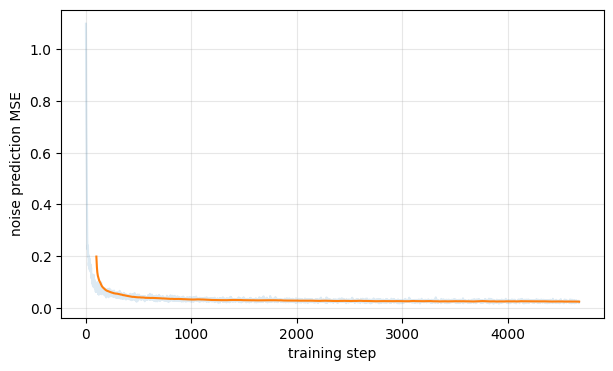

In [22]:
# 查看损失
import numpy as np

loss_array = np.array(loss_history)

window = 100

smoothed = np.convolve(
    loss_array,
    np.ones(window) / window,
    mode="valid",
)

plt.figure(figsize=(7, 4))
plt.plot(
    loss_array,
    alpha=0.15,
)
plt.plot(
    range(window - 1, len(loss_array)),
    smoothed,
)
plt.xlabel("training step")
plt.ylabel("noise prediction MSE")
plt.grid(alpha=0.3)
plt.show()

# 4. 实现带 CFG 的 DDIM 采样

In [23]:
@torch.no_grad()
def sample_conditional_ddim(
    model,
    labels,
    num_steps=50,
    guidance_scale=3.0,
    initial_noise=None,
):
    model.eval()

    labels = labels.to(device)
    n_samples = labels.shape[0]

    if initial_noise is None:
        x = torch.randn(
            n_samples,
            1,
            28,
            28,
            device=device,
        )
    else:
        x = initial_noise.clone().to(device)

    null_labels = torch.full_like(
        labels,
        null_class,
    )

    timesteps = torch.linspace(
        T - 1,
        0,
        num_steps,
        device=device,
    ).long()

    timesteps = torch.unique_consecutive(
        timesteps
    )

    timestep_list = timesteps.tolist()

    for index, t_index in enumerate(
        timestep_list
    ):
        t = torch.full(
            (n_samples,),
            t_index,
            device=device,
            dtype=torch.long,
        )

        # 有条件预测
        noise_conditional = model(
            x,
            t,
            labels,
        )

        # 无条件预测
        noise_unconditional = model(
            x,
            t,
            null_labels,
        )

        # Classifier-free guidance
        predicted_noise = (
            noise_unconditional
            + guidance_scale
            * (
                noise_conditional
                - noise_unconditional
            )
        )

        alpha_bar_t = alpha_bar[t_index]

        predicted_x0 = (
            x
            - torch.sqrt(
                1.0 - alpha_bar_t
            ) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        predicted_x0 = predicted_x0.clamp(
            -1.0,
            1.0,
        )

        if index == len(timestep_list) - 1:
            x = predicted_x0
            break

        next_t_index = timestep_list[
            index + 1
        ]

        alpha_bar_next = alpha_bar[
            next_t_index
        ]

        x = (
            torch.sqrt(alpha_bar_next)
            * predicted_x0
            + torch.sqrt(
                1.0 - alpha_bar_next
            ) * predicted_noise
        )

    return x.detach().cpu()

In [24]:
labels = torch.arange(
    10,
    device=device,
).repeat_interleave(8)

print(labels)

tensor([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2,
        3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5,
        6, 6, 6, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 7, 7, 7, 8, 8, 8, 8, 8, 8, 8, 8,
        9, 9, 9, 9, 9, 9, 9, 9], device='cuda:0')


In [25]:
samples = sample_conditional_ddim(
    conditional_model,
    labels,
    num_steps=50,
    guidance_scale=3.0,
)

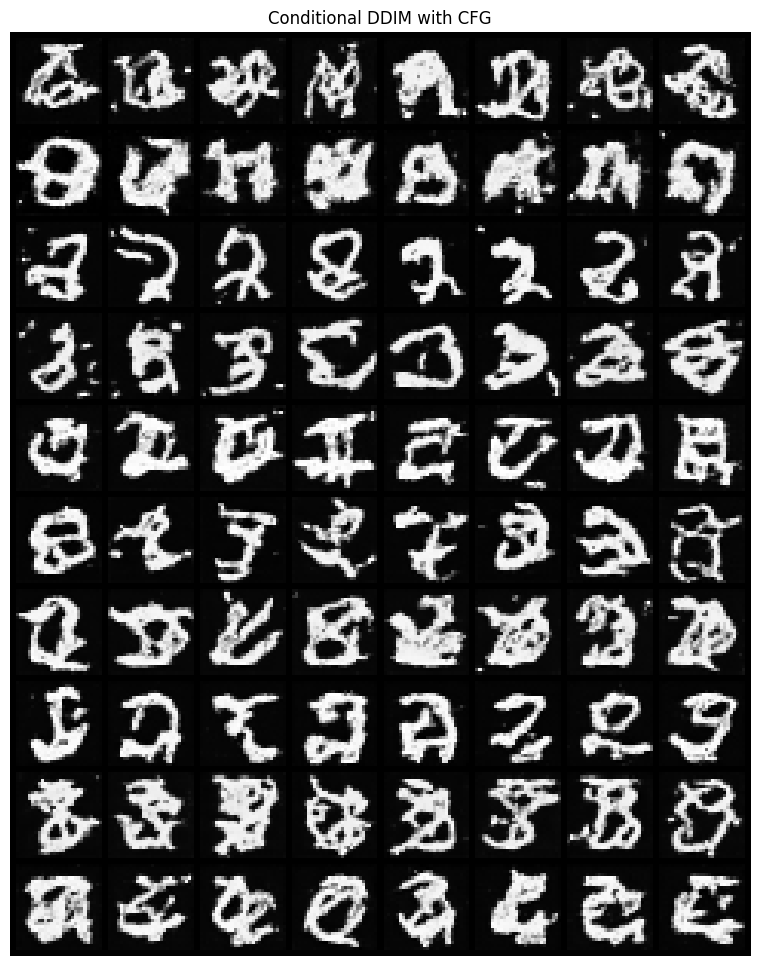

In [26]:
display_samples = (
    samples.clamp(-1, 1) + 1
) / 2

grid = make_grid(
    display_samples,
    nrow=8,
    padding=2,
)

plt.figure(figsize=(10, 12))
plt.imshow(
    grid.permute(1, 2, 0),
    cmap="gray",
)
plt.axis("off")
plt.title(
    "Conditional DDIM with CFG"
)
plt.show()